# Regresión Logistica - Ejercicio Aplicado
Vanessa Segura Cortes

Importación de librerias

In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
from sklearn.metrics import confusion_matrix
from sklearn.metrics import classification_report

Creación de Data Frame

In [5]:
datos = pd.DataFrame({
    "edad": [
        18,19,20,21,22,23,24,25,26,27,
        18,19,20,21,22,23,24,25,26,27,
        18,19,20,21,22,23,24,25,26,27,
        19,20,21,22,23,24,25,26,27,28,
        18,20,22,24,26,28,19,21,23,25
    ],

    "promedio": [
        4.5,4.2,4.0,3.8,3.6,3.9,4.3,3.7,3.5,3.2,
        4.6,4.1,3.9,3.7,3.4,3.8,4.0,3.3,3.1,2.9,
        4.7,4.3,4.1,3.9,3.5,3.6,3.8,3.2,2.8,2.7,
        4.4,4.0,3.7,3.5,3.3,3.1,3.0,2.9,2.6,2.5,
        4.8,4.2,3.6,3.4,2.9,2.7,3.8,3.2,2.8,2.4
    ],

    "asistencia": [
        95,92,90,88,85,87,94,83,82,78,
        96,91,89,86,80,84,88,79,75,72,
        97,94,91,89,81,83,86,77,70,68,
        93,90,85,82,79,74,71,69,65,62,
        98,93,84,80,73,67,87,76,70,60
    ],

    "materias_perdidas": [
        0,0,1,1,1,0,0,2,1,2,
        0,1,1,1,2,1,0,2,3,3,
        0,0,1,1,2,2,1,3,4,4,
        0,1,1,2,2,3,3,4,4,5,
        0,1,2,2,3,4,1,3,4,5
    ],

    "horas_estudio": [
        15,14,13,12,12,11,16,10,11,9,
        17,13,12,11,9,10,14,8,7,6,
        18,15,14,12,9,10,11,7,6,5,
        16,13,11,9,8,7,6,5,4,4,
        20,15,10,8,6,5,12,7,5,3
    ],

    "deserta": [
        0,0,0,0,0,0,0,0,0,1,
        0,0,0,0,1,0,0,1,1,1,
        0,0,0,0,1,0,0,1,1,1,
        0,0,0,1,1,1,1,1,1,1,
        0,0,1,1,1,1,0,1,1,1
    ]
})

datos.head()

,edad,promedio,asistencia,materias_perdidas,horas_estudio,deserta
0,18,4.5,95,0,15,0
1,19,4.2,92,0,14,0
2,20,4.0,90,1,13,0
3,21,3.8,88,1,12,0
4,22,3.6,85,1,12,0


Exploración de información

In [6]:
datos.info()
datos.describe()
datos["deserta"].value_counts()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50 entries, 0 to 49
Data columns (total 6 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   edad               50 non-null     int64  
 1   promedio           50 non-null     float64
 2   asistencia         50 non-null     int64  
 3   materias_perdidas  50 non-null     int64  
 4   horas_estudio      50 non-null     int64  
 5   deserta            50 non-null     int64  
dtypes: float64(1), int64(5)
memory usage: 2.5 KB


,count
deserta,
0,27
1,23


Relación entre variables

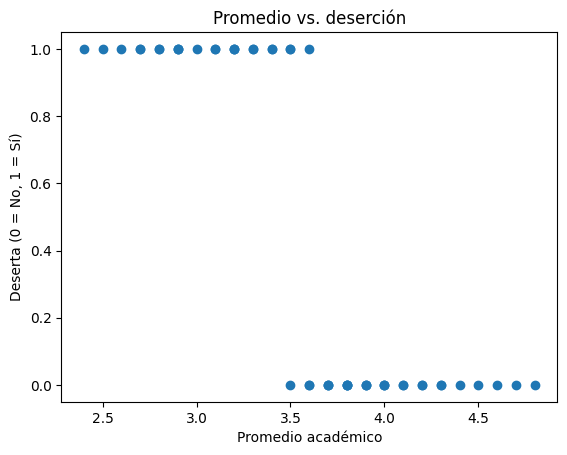

In [7]:
plt.scatter(datos["promedio"], datos["deserta"])
plt.xlabel("Promedio académico")
plt.ylabel("Deserta (0 = No, 1 = Sí)")
plt.title("Promedio vs. deserción")
plt.show()

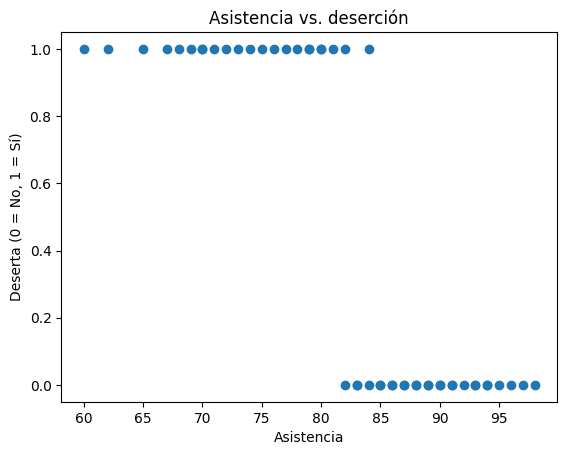

In [8]:
plt.scatter(datos["asistencia"], datos["deserta"])
plt.xlabel("Asistencia")
plt.ylabel("Deserta (0 = No, 1 = Sí)")
plt.title("Asistencia vs. deserción")
plt.show()

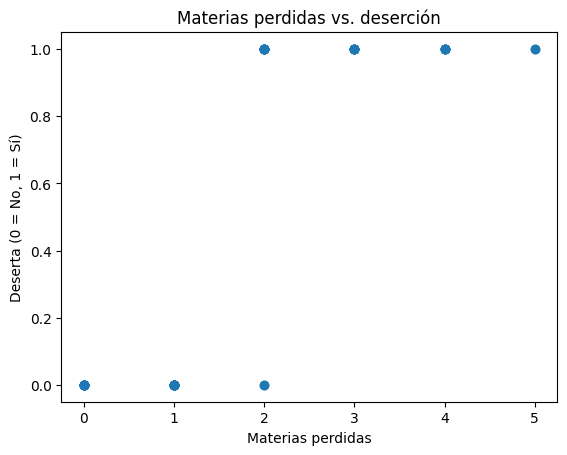

In [9]:
plt.scatter(datos["materias_perdidas"], datos["deserta"])
plt.xlabel("Materias perdidas")
plt.ylabel("Deserta (0 = No, 1 = Sí)")
plt.title("Materias perdidas vs. deserción")
plt.show()

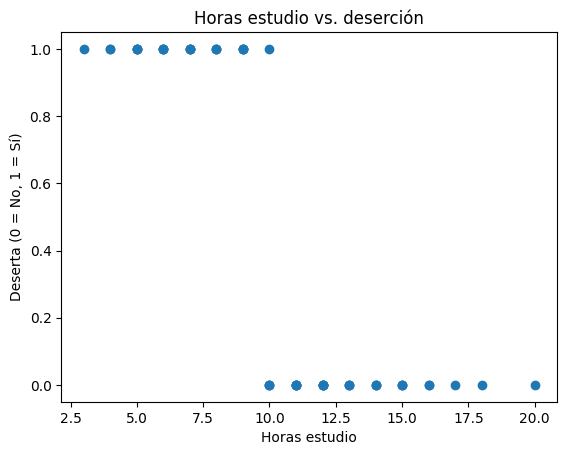

In [10]:
plt.scatter(datos["horas_estudio"], datos["deserta"])
plt.xlabel("Horas estudio")
plt.ylabel("Deserta (0 = No, 1 = Sí)")
plt.title("Horas estudio vs. deserción")
plt.show()

Definición de variables

In [11]:
X = datos[["edad", "promedio", "asistencia","materias_perdidas","horas_estudio"]]
y = datos["deserta"]
print(X.head())
print(y.head())

   edad  promedio  asistencia  materias_perdidas  horas_estudio
0    18       4.5          95                  0             15
1    19       4.2          92                  0             14
2    20       4.0          90                  1             13
3    21       3.8          88                  1             12
4    22       3.6          85                  1             12
0    0
1    0
2    0
3    0
4    0
Name: deserta, dtype: int64


Separación de Datos

In [12]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.25,
    random_state=42,
    stratify=y
)

print("Tamaño de X_train:", X_train.shape)
print("Tamaño de X_test:", X_test.shape)

print("\nDistribución de clases en entrenamiento:")
print(y_train.value_counts())

print("\nDistribución de clases en prueba:")
print(y_test.value_counts())

Tamaño de X_train: (37, 5)
Tamaño de X_test: (13, 5)

Distribución de clases en entrenamiento:
deserta
0    20
1    17
Name: count, dtype: int64

Distribución de clases en prueba:
deserta
0    7
1    6
Name: count, dtype: int64


Creación de modelo

In [13]:
modelo = LogisticRegression()
modelo.fit(X_train, y_train)

LogisticRegression()

In [14]:
y_pred = modelo.predict(X_test)
probabilidades = modelo.predict_proba(X_test)
print("Clases predichas:")
print(y_pred)
print("Probabilidades:")
print(probabilidades)

Clases predichas:
[0 0 0 0 1 0 1 0 1 1 1 0 0]
Probabilidades:
[[8.44442654e-01 1.55557346e-01]
 [8.25980920e-01 1.74019080e-01]
 [7.28379415e-01 2.71620585e-01]
 [9.95391482e-01 4.60851821e-03]
 [2.86289317e-01 7.13710683e-01]
 [9.99999934e-01 6.60568879e-08]
 [9.52149470e-11 1.00000000e+00]
 [9.99953155e-01 4.68453301e-05]
 [1.90048399e-09 9.99999998e-01]
 [1.86472355e-05 9.99981353e-01]
 [5.38375674e-05 9.99946162e-01]
 [9.94374410e-01 5.62558964e-03]
 [9.99912255e-01 8.77446961e-05]]


Comparación

In [16]:
comparacion = pd.DataFrame({
    "Real": y_test.values,
    "Predicho": y_pred,
    "Probabilidad_No_Deserta": probabilidades[:, 0],
    "Probabilidad_Deserta": probabilidades[:, 1]
})

comparacion

,Real,Predicho,Probabilidad_No_Deserta,Probabilidad_Deserta
0,1,0,8.444427e-01,1.555573e-01
1,0,0,8.259809e-01,1.740191e-01
2,0,0,7.283794e-01,2.716206e-01
3,0,0,9.953915e-01,4.608518e-03
4,1,1,2.862893e-01,7.137107e-01
5,0,0,9.999999e-01,6.605689e-08
6,1,1,9.521495e-11,1.000000e+00
7,0,0,9.999532e-01,4.684533e-05
8,1,1,1.900484e-09,1.000000e+00
9,1,1,1.864724e-05,9.999814e-01


Evaluación de modelo

In [17]:

accuracy = accuracy_score(y_test, y_pred)
print("Accuracy:", accuracy)

matriz = confusion_matrix(y_test, y_pred)
print("\nMatriz de confusión:")
print(matriz)

print("\nReporte de clasificación:")
print(classification_report(y_test, y_pred, zero_division=0))

Accuracy: 0.9230769230769231

Matriz de confusión:
[[7 0]
 [1 5]]

Reporte de clasificación:
              precision    recall  f1-score   support

           0       0.88      1.00      0.93         7
           1       1.00      0.83      0.91         6

    accuracy                           0.92        13
   macro avg       0.94      0.92      0.92        13
weighted avg       0.93      0.92      0.92        13



Umbral de decisión

In [18]:
prob_deserta = probabilidades[:, 1]

umbral = 0.60

y_pred_umbral_60 = (prob_deserta >= umbral).astype(int)

comparacion_umbral = pd.DataFrame({
    "Real": y_test.values,
    "Probabilidad_Deserta": prob_deserta,
    "Predicho_umbral_0_60": y_pred_umbral_60
})

comparacion_umbral

,Real,Probabilidad_Deserta,Predicho_umbral_0_60
0,1,1.555573e-01,0
1,0,1.740191e-01,0
2,0,2.716206e-01,0
3,0,4.608518e-03,0
4,1,7.137107e-01,1
5,0,6.605689e-08,0
6,1,1.000000e+00,1
7,0,4.684533e-05,0
8,1,1.000000e+00,1
9,1,9.999814e-01,1
